In [ ]:
import numpy as np
import pandas as pd
from sklearn import set_config
set_config(transform_output="pandas")
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('pargi_voters_natural_full_uploaded.csv',usecols=['age','distance_from_assigned_polling_booth_km','voted_status'])
df.shape


In [ ]:
df.head()

In [15]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()
df['voted_status']=lb.fit_transform(df['voted_status'])
df=df.dropna()
df.shape

(128901, 3)

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df1 = pd.DataFrame(
    scaler.fit_transform(df[['age', 'distance_from_assigned_polling_booth_km']]),
    columns=['age', 'distance_from_assigned_polling_booth_km']
)

df1['voted_status'] = df['voted_status'].values

df1.head()

,age,distance_from_assigned_polling_booth_km,voted_status
0,0.671467,0.993576,1
1,-1.285252,1.115015,0
2,-1.335424,0.210964,0
3,-1.134735,-0.814527,0
4,1.474223,-0.855007,1


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X = df1.drop('voted_status', axis=1)
y = df1['voted_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

lr = LogisticRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

accuracy_score(y_test, y_pred)

0.8642652116573143

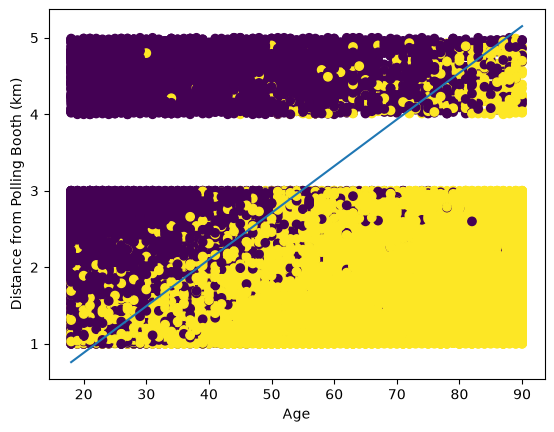

In [18]:
x = np.linspace(df['age'].min(), df['age'].max(), 100)

x_scaled = scaler.transform(
    pd.DataFrame({
        'age': x,
        'distance_from_assigned_polling_booth_km': np.zeros(100)
    })
).iloc[:, 0]

y_scaled = -(lr.intercept_[0] + lr.coef_[0][0] * x_scaled) / lr.coef_[0][1]

y_line = y_scaled * scaler.scale_[1] + scaler.mean_[1]

plt.scatter(df['age'], df['distance_from_assigned_polling_booth_km'], c=y)
plt.plot(x, y_line)
plt.xlabel('Age')
plt.ylabel('Distance from Polling Booth (km)')
plt.show()

In [19]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier


In [21]:
import optuna

In [22]:
def objective(trial):

    classifier_name = trial.suggest_categorical(
        'classifier',
        [
            'SVM',
            'RandomForest',
            'GradientBoosting',
            'StackingClassifier',
            'VotingClassifier',
            'AdaBoostClassifier',
            'BaggingClassifier',
            'KNeighborsClassifier',
            'XGBClassifier',
            'DecisionTreeClassifier',
            'GaussianNB'
        ]
    )

    # =========================================================
    # 1. SVM
    # =========================================================
    if classifier_name == 'SVM':

        C = trial.suggest_float(
            'svm_C', 0.001, 1000, log=True
        )

        kernel = trial.suggest_categorical(
            'svm_kernel',
            ['linear', 'rbf', 'poly', 'sigmoid']
        )

        gamma = trial.suggest_categorical(
            'svm_gamma',
            ['scale', 'auto']
        )

        degree = trial.suggest_int(
            'svm_degree', 2, 5
        )

        coef0 = trial.suggest_float(
            'svm_coef0', 0.0, 2.0
        )

        class_weight = trial.suggest_categorical(
            'svm_class_weight',
            [None, 'balanced']
        )

        model = SVC(
            C=C,
            kernel=kernel,
            gamma=gamma,
            degree=degree,
            coef0=coef0,
            class_weight=class_weight,
            random_state=42
        )


    # =========================================================
    # 2. RANDOM FOREST
    # =========================================================
    elif classifier_name == 'RandomForest':

        n_estimators = trial.suggest_int(
            'rf_n_estimators', 100, 1000
        )

        max_depth = trial.suggest_int(
            'rf_max_depth', 2, 50
        )

        min_samples_split = trial.suggest_int(
            'rf_min_samples_split', 2, 20
        )

        min_samples_leaf = trial.suggest_int(
            'rf_min_samples_leaf', 1, 20
        )

        max_features = trial.suggest_categorical(
            'rf_max_features',
            ['sqrt', 'log2', None]
        )

        bootstrap = trial.suggest_categorical(
            'rf_bootstrap',
            [True, False]
        )

        criterion = trial.suggest_categorical(
            'rf_criterion',
            ['gini', 'entropy', 'log_loss']
        )

        class_weight = trial.suggest_categorical(
            'rf_class_weight',
            [None, 'balanced', 'balanced_subsample']
        )

        max_leaf_nodes = trial.suggest_categorical(
            'rf_max_leaf_nodes',
            [None, 10, 20, 30, 50, 100]
        )

        min_impurity_decrease = trial.suggest_float(
            'rf_min_impurity_decrease',
            0.0, 0.05
        )

        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            bootstrap=bootstrap,
            criterion=criterion,
            class_weight=class_weight,
            max_leaf_nodes=max_leaf_nodes,
            min_impurity_decrease=min_impurity_decrease,
            random_state=42,
            n_jobs=-1
        )


    # =========================================================
    # 3. GRADIENT BOOSTING
    # =========================================================
    elif classifier_name == 'GradientBoosting':

        n_estimators = trial.suggest_int(
            'gb_n_estimators', 50, 1000
        )

        learning_rate = trial.suggest_float(
            'gb_learning_rate', 0.001, 0.3, log=True
        )

        max_depth = trial.suggest_int(
            'gb_max_depth', 1, 20
        )

        min_samples_split = trial.suggest_int(
            'gb_min_samples_split', 2, 30
        )

        min_samples_leaf = trial.suggest_int(
            'gb_min_samples_leaf', 1, 20
        )

        subsample = trial.suggest_float(
            'gb_subsample', 0.5, 1.0
        )

        max_features = trial.suggest_categorical(
            'gb_max_features',
            [None, 'sqrt', 'log2']
        )

        criterion = trial.suggest_categorical(
            'gb_criterion',
            ['friedman_mse', 'squared_error']
        )

        min_impurity_decrease = trial.suggest_float(
            'gb_min_impurity_decrease',
            0.0, 0.05
        )

        model = GradientBoostingClassifier(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            subsample=subsample,
            max_features=max_features,
            criterion=criterion,
            min_impurity_decrease=min_impurity_decrease,
            random_state=42
        )


    # =========================================================
    # 4. ADA BOOST
    # =========================================================
    elif classifier_name == 'AdaBoostClassifier':

        n_estimators = trial.suggest_int(
            'ada_n_estimators', 50, 1000
        )

        learning_rate = trial.suggest_float(
            'ada_learning_rate', 0.001, 2.0, log=True
        )

        model = AdaBoostClassifier(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            random_state=42
        )


    # =========================================================
    # 5. BAGGING
    # =========================================================
    elif classifier_name == 'BaggingClassifier':

        n_estimators = trial.suggest_int(
            'bag_n_estimators', 10, 500
        )

        max_samples = trial.suggest_float(
            'bag_max_samples', 0.3, 1.0
        )

        max_features = trial.suggest_float(
            'bag_max_features', 0.3, 1.0
        )

        bootstrap = trial.suggest_categorical(
            'bag_bootstrap',
            [True, False]
        )

        bootstrap_features = trial.suggest_categorical(
            'bag_bootstrap_features',
            [True, False]
        )

        model = BaggingClassifier(
            n_estimators=n_estimators,
            max_samples=max_samples,
            max_features=max_features,
            bootstrap=bootstrap,
            bootstrap_features=bootstrap_features,
            random_state=42,
            n_jobs=-1
        )


    # =========================================================
    # 6. K NEAREST NEIGHBORS
    # =========================================================
    elif classifier_name == 'KNeighborsClassifier':

        n_neighbors = trial.suggest_int(
            'knn_n_neighbors', 1, 50
        )

        weights = trial.suggest_categorical(
            'knn_weights',
            ['uniform', 'distance']
        )

        algorithm = trial.suggest_categorical(
            'knn_algorithm',
            ['auto', 'ball_tree', 'kd_tree', 'brute']
        )

        leaf_size = trial.suggest_int(
            'knn_leaf_size', 10, 100
        )

        p = trial.suggest_int(
            'knn_p', 1, 5
        )

        model = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            algorithm=algorithm,
            leaf_size=leaf_size,
            p=p
        )


    # =========================================================
    # 7. XGBOOST
    # =========================================================
    elif classifier_name == 'XGBClassifier':

        n_estimators = trial.suggest_int(
            'xgb_n_estimators', 100, 1500
        )

        max_depth = trial.suggest_int(
            'xgb_max_depth', 1, 20
        )

        learning_rate = trial.suggest_float(
            'xgb_learning_rate', 0.001, 0.3, log=True
        )

        min_child_weight = trial.suggest_float(
            'xgb_min_child_weight', 0.1, 20, log=True
        )

        subsample = trial.suggest_float(
            'xgb_subsample', 0.5, 1.0
        )

        colsample_bytree = trial.suggest_float(
            'xgb_colsample_bytree', 0.5, 1.0
        )

        gamma = trial.suggest_float(
            'xgb_gamma', 0.0, 10.0
        )

        reg_alpha = trial.suggest_float(
            'xgb_reg_alpha', 1e-8, 10, log=True
        )

        reg_lambda = trial.suggest_float(
            'xgb_reg_lambda', 1e-8, 10, log=True
        )

        max_delta_step = trial.suggest_int(
            'xgb_max_delta_step', 0, 10
        )

        booster = trial.suggest_categorical(
            'xgb_booster',
            ['gbtree', 'dart']
        )

        model = XGBClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            learning_rate=learning_rate,
            min_child_weight=min_child_weight,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            gamma=gamma,
            reg_alpha=reg_alpha,
            reg_lambda=reg_lambda,
            max_delta_step=max_delta_step,
            booster=booster,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        )


    # =========================================================
    # 8. DECISION TREE
    # =========================================================
    elif classifier_name == 'DecisionTreeClassifier':

        criterion = trial.suggest_categorical(
            'dt_criterion',
            ['gini', 'entropy', 'log_loss']
        )

        splitter = trial.suggest_categorical(
            'dt_splitter',
            ['best', 'random']
        )

        max_depth = trial.suggest_int(
            'dt_max_depth', 1, 50
        )

        min_samples_split = trial.suggest_int(
            'dt_min_samples_split', 2, 30
        )

        min_samples_leaf = trial.suggest_int(
            'dt_min_samples_leaf', 1, 20
        )

        max_features = trial.suggest_categorical(
            'dt_max_features',
            [None, 'sqrt', 'log2']
        )

        max_leaf_nodes = trial.suggest_categorical(
            'dt_max_leaf_nodes',
            [None, 5, 10, 20, 30, 50, 100]
        )

        min_impurity_decrease = trial.suggest_float(
            'dt_min_impurity_decrease',
            0.0, 0.05
        )

        class_weight = trial.suggest_categorical(
            'dt_class_weight',
            [None, 'balanced']
        )

        ccp_alpha = trial.suggest_float(
            'dt_ccp_alpha',
            0.0, 0.05
        )

        model = DecisionTreeClassifier(
            criterion=criterion,
            splitter=splitter,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            max_leaf_nodes=max_leaf_nodes,
            min_impurity_decrease=min_impurity_decrease,
            class_weight=class_weight,
            ccp_alpha=ccp_alpha,
            random_state=42
        )


    # =========================================================
    # 9. GAUSSIAN NB
    # =========================================================
    elif classifier_name == 'GaussianNB':

        var_smoothing = trial.suggest_float(
            'gnb_var_smoothing',
            1e-12, 1e-6, log=True
        )

        model = GaussianNB(
            var_smoothing=var_smoothing
        )


    # =========================================================
    # 10. VOTING CLASSIFIER
    # =========================================================
    elif classifier_name == 'VotingClassifier':

        voting = trial.suggest_categorical(
            'voting_type',
            ['hard', 'soft']
        )

        # Tune the important base models
        rf_n_estimators = trial.suggest_int(
            'vote_rf_n_estimators', 100, 500
        )

        rf_max_depth = trial.suggest_int(
            'vote_rf_max_depth', 2, 30
        )

        svm_C = trial.suggest_float(
            'vote_svm_C', 0.01, 100, log=True
        )

        knn_neighbors = trial.suggest_int(
            'vote_knn_neighbors', 2, 30
        )

        rf = RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            random_state=42,
            n_jobs=-1
        )

        svm = SVC(
            C=svm_C,
            probability=True,
            random_state=42
        )

        knn = KNeighborsClassifier(
            n_neighbors=knn_neighbors
        )

        model = VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm),
                ('knn', knn)
            ],
            voting=voting
        )


    # =========================================================
    # 11. STACKING CLASSIFIER
    # =========================================================
    elif classifier_name == 'StackingClassifier':

        rf_n_estimators = trial.suggest_int(
            'stack_rf_n_estimators', 100, 500
        )

        rf_max_depth = trial.suggest_int(
            'stack_rf_max_depth', 2, 30
        )

        svm_C = trial.suggest_float(
            'stack_svm_C', 0.01, 100, log=True
        )

        knn_neighbors = trial.suggest_int(
            'stack_knn_neighbors', 2, 30
        )

        final_C = trial.suggest_float(
            'stack_final_C', 0.01, 100, log=True
        )

        rf = RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            random_state=42,
            n_jobs=-1
        )

        svm = SVC(
            C=svm_C,
            probability=True,
            random_state=42
        )

        knn = KNeighborsClassifier(
            n_neighbors=knn_neighbors
        )

        final_estimator = LogisticRegression(
            C=final_C,
            max_iter=2000
        )

        model = StackingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm),
                ('knn', knn)
            ],
            final_estimator=final_estimator,
            cv=5,
            n_jobs=-1
        )


    # =========================================================
    # CROSS VALIDATION
    # =========================================================

    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    ).mean()

    return score

In [23]:
from sklearn.model_selection import cross_val_score

In [65]:
print("Best Accuracy:", study.best_value)
print("Best Parameters:")
print(study.best_params)

Best Accuracy: 0.9257142857142858
Best Parameters:
{'classifier': 'SVM', 'svm_C': 0.23481164426718876, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 2, 'svm_coef0': 1.2629592477952185, 'svm_class_weight': None}


In [ ]:


s = SVC(C=0.23481164426718876,kernel='rbf',gamma='auto')

In [95]:
s.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.23481164426718876
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [96]:
y_pred5=s.predict(X_test)

In [97]:
accuracy_score(y_pred5,y_test)

0.8866666666666667

C:\Users\shrim\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


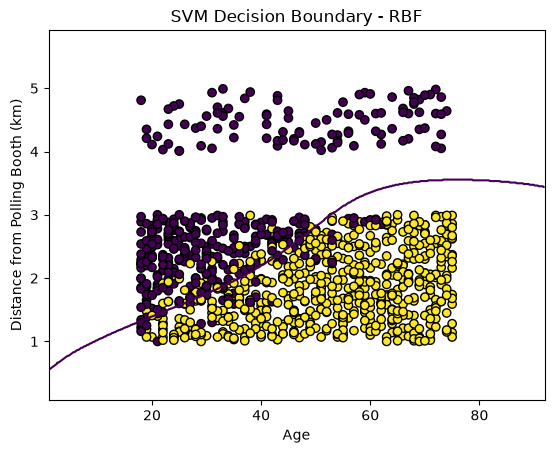

In [99]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

s = SVC(
    C=0.23481164426718876,
    kernel='rbf',
    gamma='auto'
)

# Train on scaled data
s.fit(X, y)

# Grid in scaled space
x_min = X.iloc[:, 0].min() - 1
x_max = X.iloc[:, 0].max() + 1

y_min = X.iloc[:, 1].min() - 1
y_max = X.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict in scaled space
Z = s.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Convert DATA points back to original values
X_original = scaler.inverse_transform(X)

# Convert GRID back to original values
grid_original = scaler.inverse_transform(
    np.c_[xx.ravel(), yy.ravel()]
)

xx_original = grid_original[:, 0].reshape(xx.shape)
yy_original = grid_original[:, 1].reshape(yy.shape)

# Plot
plt.scatter(
    X_original[:, 0],
    X_original[:, 1],
    c=y,
    edgecolors='k'
)

# RBF decision boundary
plt.contour(
    xx_original,
    yy_original,
    Z,
    levels=[0.5]
)

plt.xlabel('Age')
plt.ylabel('Distance from Polling Booth (km)')
plt.title('SVM Decision Boundary - RBF')
plt.show()